<a href="https://colab.research.google.com/github/ghirr/Smart-Traffic-Flow-Prediction-and-Optimization/blob/main/Smart_Traffic_Flow_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Smart Traffic Flow Prediction and Optimization**

# Partie 1 : Data Understanding, Exploration and Preparation

**Plan du notebook**

| # | Section | Ce qu'on y fait |
|---|---|---|
| 0 | Problématique et objectifs | formulation du problème, choix de modélisation |
| 1 | Chargement et présentation du dataset | schéma, taille, granularité temporelle |
| 2 | Qualité des données | manquants, doublons, constantes, règles de validité, cohérence des trajectoires |
| 3 | Valeurs aberrantes | IQR, z-score, règles physiques |
| 4 | Analyse exploratoire (EDA) | distributions, déséquilibre, relations, carte spatiale, dynamique temporelle |
| 5 | Nettoyage | fonction `nettoyer(df)` appliquée dans un ordre fixe |
| 6 | Feature Engineering | variables par véhicule puis agrégation par cellule spatiale × fenêtre de temps |
| 7 | Cibles et découpage train / validation / test | découpage **chronologique**, sans fuite |
| 8 | Imputation, encodage, sélection, normalisation, PCA | tout est ajusté sur le **train uniquement** |
| 9 | Sauvegarde et rapport qualité | jeux prêts pour les parties 2 (Ensemble Learning) et 3 (ANN) |

## 0. Problématique et objectifs

**Contexte.** Le dataset `HEU-101092696-CODECO-Trajectories.csv` contient les trajectoires de véhicules d'une simulation de trafic urbain (une ligne = un véhicule à une seconde donnée : position, vitesse, direction, voie).

**Problématique.** Anticiper l'état du trafic sur le réseau pour pouvoir le fluidifier : *combien de véhicules vont se trouver dans chaque zone de la ville dans la minute qui vient, et à quelle vitesse vont-ils rouler ?*

**Objectifs de cette partie.**
1. Comprendre le dataset et vérifier sa qualité.
2. Explorer les distributions, les corrélations et la structure spatio-temporelle.
3. Transformer des trajectoires individuelles (3,9 M de lignes) en un jeu **supervisé** exploitable par des modèles de Machine Learning.
4. Produire des jeux `train / validation / test` **sans fuite de données**.

**Choix de modélisation (à justifier dans le rapport).**

- *Unité d'analyse* : une **cellule spatiale de 100 m × 100 m** observée sur une **fenêtre de 60 secondes**. Une analyse par voie (`lane_id`, 2 482 voies) donnerait des fenêtres presque vides : environ 166 véhicules sont présents à un instant donné, soit en moyenne 0,07 véhicule par voie. La grille spatiale donne des comptages plus stables et permet d'utiliser les cellules voisines comme variables.
- *Cibles* (minute suivante, pour chaque cellule) :
  - `speed_next` : vitesse moyenne (régression) ;
  - `n_veh_next` : nombre de véhicules distincts, c'est-à-dire le **flux** (régression) ;
  - `etat_next` : état du trafic `congestionné / ralenti / fluide` (classification, seuils calculés sur le train).
- *Découpage* : **chronologique**. Un découpage aléatoire mélangerait des minutes consécutives, très corrélées entre elles, et surestimerait les performances.
- Les paramètres (`CELL`, `WINDOW`, `N_LAGS`...) sont regroupés dans la première cellule de code : on peut les changer et tout relancer.

In [3]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from numpy import isnan
from pandas import read_csv
from scipy import stats
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, f_regression, mutual_info_regression, chi2
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

# ----- Paramètres de modélisation (modifiables) -----
SEED        = 42        # reproductibilité
CELL        = 100       # taille d'une cellule de la grille (mètres)
WINDOW      = 60        # durée d'une fenêtre d'agrégation (secondes)
N_LAGS      = 3         # nombre de fenêtres passées utilisées comme variables
V_MAX_IMPL  = 25.0      # m/s (90 km/h) : au-delà, un déplacement entre 2 positions est physiquement impossible (vitesse max observée : 18,7 m/s)
WARMUP_S    = 600       # secondes de « montée en charge » du réseau, exclues de la modélisation
HARD_BRAKE  = -3.0      # m/s² : seuil de freinage brusque
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15   # le reste (15 %) = test
OUT_DIR     = "data_prepared"

np.random.seed(SEED)

## 1. Chargement et présentation du dataset

Le fichier fait environ 447 Mo : trop gros pour GitHub. Sur Colab, placez-le dans la session (`/content`) ou dans Google Drive (`MyDrive/` ou `MyDrive/ML_Project/`). La cellule ci-dessous le cherche à ces emplacements et monte Drive si besoin.

On fixe les types à la lecture (`float32`, `category`) pour réduire la mémoire : environ 100 Mo au lieu de plus de 1 Go.

In [4]:
FILE = "HEU-101092696-CODECO-Trajectories.csv"
candidats = [os.environ.get("TRAFFIC_CSV", ""), FILE, f"/content/{FILE}",
             f"/content/drive/MyDrive/{FILE}", f"/content/drive/MyDrive/ML_Project/{FILE}"]

if "google.colab" in sys.modules and not any(c and os.path.exists(c) for c in candidats):
    from google.colab import drive
    drive.mount("/content/drive")

DATA_PATH = next((c for c in candidats if c and os.path.exists(c)), None)
assert DATA_PATH, f"Fichier introuvable : placez {FILE} dans /content ou dans Drive (MyDrive/ML_Project/)."

dtypes = {"step": "int32", "id": "category", "x": "float32", "y": "float32",
          "speed": "float32", "angle": "float32", "lane_id": "category", "type": "category"}
dt = read_csv(DATA_PATH, dtype=dtypes)
dt.head()

,step,id,x,y,speed,angle,lane_id,type
0,0,veh0,470.490936,722.513794,0.000000,323.006775,288595616_0,veh_passenger
1,1,veh0,469.352539,724.024841,1.891703,323.006775,288595616_0,veh_passenger
2,2,veh0,467.735626,726.171082,2.686898,323.006775,288595616_0,veh_passenger
3,3,veh0,466.729248,727.506958,1.672368,323.006775,288595616_0,veh_passenger
4,3,veh1,1485.124023,380.426239,0.000000,46.493462,1370026143#1_2,veh_passenger


In [5]:
print("Dimensions :", dt.shape)
print("Colonnes   :", list(dt.columns))
dt.info(memory_usage="deep")

Dimensions : (3921776, 8)
Colonnes   : ['step', 'id', 'x', 'y', 'speed', 'angle', 'lane_id', 'type']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3921776 entries, 0 to 3921775
Data columns (total 8 columns):
 #   Column   Dtype   
---  ------   -----   
 0   step     int32   
 1   id       category
 2   x        float32 
 3   y        float32 
 4   speed    float32 
 5   angle    float32 
 6   lane_id  category
 7   type     category
dtypes: category(3), float32(4), int32(1)
memory usage: 94.5 MB


**Description des colonnes** (simulation de type SUMO)

| Colonne | Type | Signification | Rôle dans le projet |
|---|---|---|---|
| `step` | entier | seconde de simulation | axe du temps |
| `id` | catégorie | identifiant du véhicule (`veh0`, `veh1`...) | identifiant, **pas une variable explicative** |
| `x`, `y` | réel | position du véhicule (mètres, repère de la simulation) | localisation, grille spatiale |
| `speed` | réel | vitesse instantanée (m/s) | cible principale (en moyenne par zone) |
| `angle` | réel | cap du véhicule (degrés, 0 à 360) | direction, variable **circulaire** |
| `lane_id` | catégorie | voie occupée : `<route>_<n° de voie>`, un identifiant commençant par `:` désigne l'intérieur d'une intersection | contexte routier |
| `type` | catégorie | type de véhicule | à vérifier (constante ?) |

**Il n'y a pas de variable cible dans le fichier brut** : les cibles du projet (flux, vitesse moyenne, état du trafic) se construisent par agrégation, sections 6 et 7.

In [6]:
# Granularité temporelle : l'écart entre deux observations consécutives d'un même véhicule
dt = dt.sort_values(["id", "step"], ignore_index=True)
ecart = dt.groupby("id", observed=True)["step"].diff()
print("Écarts de temps entre observations d'un même véhicule (secondes) :")
print(ecart.value_counts().head(6).to_string())

duree_h = (dt.step.max() - dt.step.min() + 1) / 3600
print(f"\nSimulation : steps {dt.step.min()} à {dt.step.max()} ({dt.step.nunique()} instants distincts) = {duree_h:.2f} heures")
print(f"Véhicules distincts : {dt.id.nunique():,}   |   Voies distinctes : {dt.lane_id.nunique():,}")
print(f"Véhicules présents simultanément (moyenne) : {dt.groupby('step').size().mean():.0f}")

Écarts de temps entre observations d'un même véhicule (secondes) :
step
1.0     3911867
3.0          11
4.0          11
53.0          5
2.0           4
36.0          3

Simulation : steps 0 à 23583 (23584 instants distincts) = 6.55 heures
Véhicules distincts : 9,863   |   Voies distinctes : 2,482
Véhicules présents simultanément (moyenne) : 166


## 2. Qualité des données

### 2.1 Valeurs manquantes, doublons, colonnes constantes

In [7]:
manquants = pd.DataFrame({"n_manquants": dt.isna().sum(), "pct": 100 * dt.isna().mean()})
print(manquants.to_string())

n_dup_total = int(dt.duplicated().sum())
n_dup_cle   = int(dt.duplicated(["step", "id"]).sum())   # un véhicule ne peut être qu'à un seul endroit à un instant donné
print(f"\nLignes dupliquées (toutes colonnes)       : {n_dup_total}")
print(f"Doublons sur la clé (step, id)             : {n_dup_cle}")

constantes = [c for c in dt.columns if dt[c].nunique() == 1]
print(f"Colonnes constantes                        : {constantes} -> valeur : {dt[constantes[0]].iloc[0] if constantes else None}")

         n_manquants  pct
step               0  0.0
id                 0  0.0
x                  0  0.0
y                  0  0.0
speed              0  0.0
angle              0  0.0
lane_id            0  0.0
type               0  0.0

Lignes dupliquées (toutes colonnes)       : 0
Doublons sur la clé (step, id)             : 0
Colonnes constantes                        : ['type'] -> valeur : veh_passenger


Le fichier est **complet** (aucune valeur manquante, aucun doublon). La colonne `type` ne contient qu'une seule modalité (`veh_passenger`) : elle n'apporte aucune information et sera supprimée.

Attention : un jeu sans valeur manquante n'est pas pour autant sans problème. Les cellules et fenêtres où **aucun véhicule ne passe** créeront des valeurs manquantes *structurelles* lors de l'agrégation (section 6).

### 2.2 Règles de validité (règles métier)

In [8]:
regles = pd.Series({
    "speed >= 0":                          bool((dt.speed >= 0).all()),
    "0 <= angle <= 360":                   bool(dt.angle.between(0, 360).all()),
    "x, y finies":                         bool(np.isfinite(dt[["x", "y"]]).all().all()),
    "step >= 0":                           bool((dt.step >= 0).all()),
    "vitesse max plausible (<= 25 m/s = 90 km/h, ville)": bool((dt.speed <= 25).all()),
})
print(regles.to_string())
print(f"\nEmprise spatiale : x in [{dt.x.min():.0f}, {dt.x.max():.0f}] m, y in [{dt.y.min():.0f}, {dt.y.max():.0f}] m  (soit environ {(dt.x.max()-dt.x.min())/1000:.1f} km x {(dt.y.max()-dt.y.min())/1000:.1f} km)")
print(f"Vitesse max observée : {dt.speed.max():.1f} m/s = {dt.speed.max()*3.6:.0f} km/h")

speed >= 0                                            True
0 <= angle <= 360                                     True
x, y finies                                           True
step >= 0                                             True
vitesse max plausible (<= 25 m/s = 90 km/h, ville)    True

Emprise spatiale : x in [-1, 1695] m, y in [0, 944] m  (soit environ 1.7 km x 0.9 km)
Vitesse max observée : 18.7 m/s = 67 km/h


### 2.3 Cohérence des trajectoires

Un véhicule ne peut pas se téléporter. Pour deux observations consécutives d'un même véhicule, on calcule la **vitesse implicite** (distance parcourue / temps écoulé) et on la compare à une borne physique de 25 m/s (90 km/h), alors que la vitesse maximale observée est de 18,7 m/s. Les sauts impossibles sont des artefacts de simulation (téléportations de véhicules bloqués, par exemple).

Trous temporels dans une trajectoire (écart > 1 s) : 46
Sauts de position impossibles (v. implicite > 25 m/s)  : 63  (0.0016 % des lignes)
Véhicules avec une seule observation              : 1


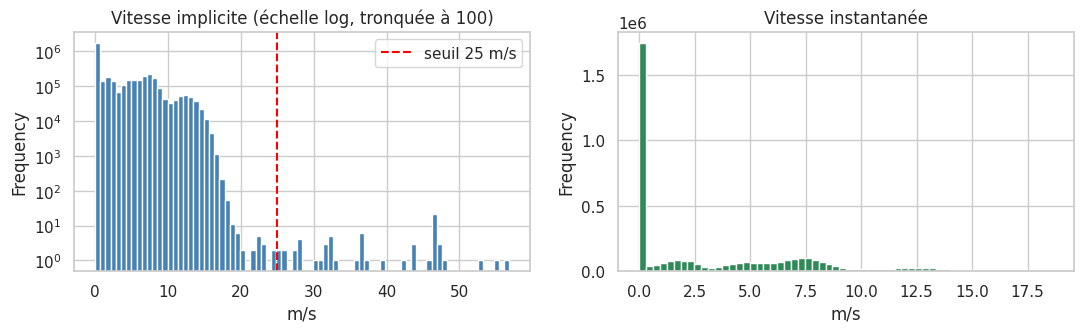

In [9]:
g = dt.groupby("id", observed=True)
dstep  = g["step"].diff()
v_impl = np.hypot(g["x"].diff(), g["y"].diff()) / dstep

n_trous = int((dstep > 1).sum())
n_tele  = int((v_impl > V_MAX_IMPL).sum())
print(f"Trous temporels dans une trajectoire (écart > 1 s) : {n_trous}")
print(f"Sauts de position impossibles (v. implicite > {V_MAX_IMPL:.0f} m/s)  : {n_tele}  ({100*n_tele/len(dt):.4f} % des lignes)")
print(f"Véhicules avec une seule observation              : {int((g.size() == 1).sum())}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
v_impl.dropna().clip(upper=100).plot.hist(bins=80, log=True, ax=ax[0], color="steelblue")
ax[0].axvline(V_MAX_IMPL, color="red", ls="--", label=f"seuil {V_MAX_IMPL:.0f} m/s"); ax[0].legend()
ax[0].set_title("Vitesse implicite (échelle log, tronquée à 100)"); ax[0].set_xlabel("m/s")
dt["speed"].plot.hist(bins=60, ax=ax[1], color="seagreen"); ax[1].set_title("Vitesse instantanée"); ax[1].set_xlabel("m/s")
plt.tight_layout(); plt.show()
del g, dstep, v_impl

## 3. Valeurs aberrantes

On applique les deux méthodes du cours (IQR et z-score) à la vitesse, puis on les **confronte à une règle physique**. Une valeur extrême statistiquement n'est pas forcément une erreur.

In [10]:
def bornes_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

lo, hi = bornes_iqr(dt.speed)
n_iqr = int(((dt.speed < lo) | (dt.speed > hi)).sum())

s64 = dt.speed.astype("float64")
z = (s64 - s64.mean()) / s64.std()
n_z = int((z.abs() > 3).sum())

print(f"IQR     : bornes [{lo:.1f}, {hi:.1f}] m/s -> {n_iqr:,} valeurs hors bornes ({100*n_iqr/len(dt):.2f} %)")
print(f"z-score : |z| > 3 (vitesse > {s64.mean()+3*s64.std():.1f} m/s) -> {n_z:,} valeurs ({100*n_z/len(dt):.2f} %)")
print(f"Vitesse maximale = {dt.speed.max():.1f} m/s = {dt.speed.max()*3.6:.0f} km/h : plausible pour une voie urbaine rapide")
del z, s64

IQR     : bornes [-9.9, 16.5] m/s -> 980 valeurs hors bornes (0.02 %)
z-score : |z| > 3 (vitesse > 15.5 m/s) -> 7,253 valeurs (0.18 %)
Vitesse maximale = 18.7 m/s = 67 km/h : plausible pour une voie urbaine rapide


**Lecture.** Les méthodes statistiques signalent une petite part de vitesses élevées (au-delà d'environ 16 m/s, soit 58 km/h). Ce sont des **véhicules qui roulent librement sur une voie rapide**, pas des erreurs : la vitesse maximale (67 km/h) reste réaliste. Les supprimer fausserait précisément ce qu'on veut prédire (le trafic fluide). **Décision : on conserve ces valeurs.**

En revanche, les **sauts de position impossibles** (section 2.3) sont de vraies anomalies : on supprime ces lignes dans `nettoyer()`.

L'accélération (variation de vitesse d'une seconde à l'autre) est examinée à la section 5, après le nettoyage.

## 4. Analyse exploratoire (EDA)

### 4.1 Statistiques descriptives

In [11]:
print(dt[["step", "x", "y", "speed", "angle"]].describe().T.to_string())
print()
print(dt[["id", "lane_id", "type"]].describe().T.to_string())

           count          mean          std       min          25%           50%           75%           max
step   3921776.0  11974.624485  6676.449165  0.000000  6164.000000  12091.000000  17723.000000  23583.000000
x      3921776.0    872.984192   356.029724 -1.338734   696.159927    867.800110   1100.102539   1694.544434
y      3921776.0    435.878571   210.233566  0.183826   255.528687    408.583389    607.993469    944.136841
speed  3921776.0      3.405776     4.053965  0.000000     0.000000      1.536675      6.605764     18.658438
angle  3921776.0    174.451965    91.826553  0.000388   135.442337    143.795944    230.683411    359.985687

           count unique            top     freq
id       3921776   9863        veh1781     2953
lane_id  3921776   2482  836361915#1_0   121570
type     3921776      1  veh_passenger  3921776


### 4.2 Distribution de la vitesse : variable à forte masse en zéro

Part des observations à l'arrêt (vitesse < 0,1 m/s) : 43.2 %
Asymétrie (skew) de la vitesse : 0.96
Médiane = 1.54 m/s, moyenne = 3.41 m/s


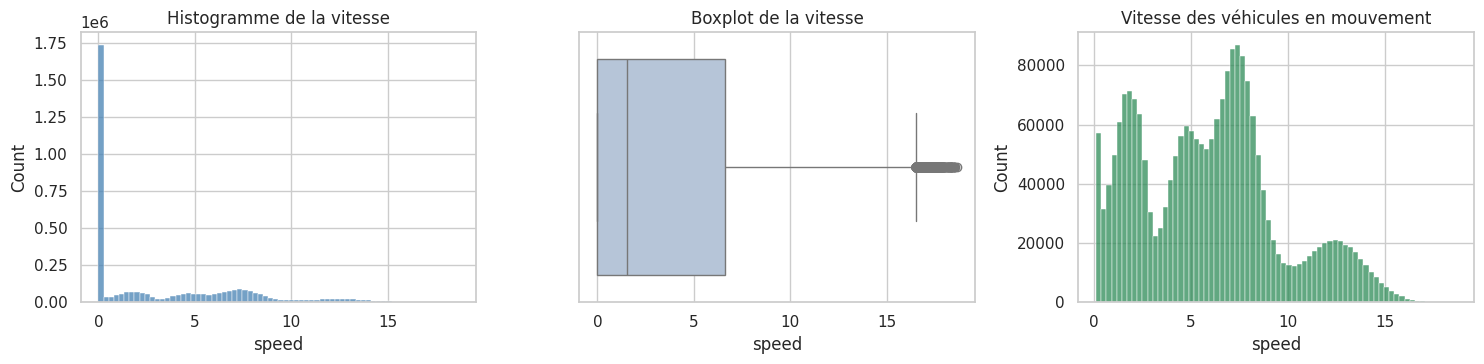

In [12]:
p_zero = (dt.speed < 0.1).mean()
print(f"Part des observations à l'arrêt (vitesse < 0,1 m/s) : {100*p_zero:.1f} %")
print(f"Asymétrie (skew) de la vitesse : {dt.speed.skew():.2f}")
print(f"Médiane = {dt.speed.median():.2f} m/s, moyenne = {dt.speed.mean():.2f} m/s")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(dt.speed, bins=70, ax=ax[0], color="steelblue"); ax[0].set_title("Histogramme de la vitesse")
sns.boxplot(x=dt.speed, ax=ax[1], color="lightsteelblue"); ax[1].set_title("Boxplot de la vitesse")
sns.histplot(dt.loc[dt.speed >= 0.1, "speed"], bins=70, ax=ax[2], color="seagreen"); ax[2].set_title("Vitesse des véhicules en mouvement")
plt.tight_layout(); plt.show()

**Observation.** Plus de 4 observations sur 10 (43 %) correspondent à un véhicule **à l'arrêt** (feux, files d'attente) : un pic énorme à 0. Pour les véhicules en mouvement, on voit **trois régimes** de vitesse : autour de 2 m/s (circulation très lente), de 7 m/s et de 12 m/s (voies rapides), ce qui reflète des types de routes différents. Une moyenne seule cache cette structure, c'est pourquoi on construira aussi la part de véhicules arrêtés (`p_stopped`) comme variable, et un état de trafic discret en cible.

### 4.3 Dynamique temporelle

      vitesse_moy  n_lignes  p_arret  vehicules_actifs_moy
step                                                      
0            3.58    535748     0.41                148.82
1            3.41    616089     0.43                171.14
2            3.47    589497     0.42                163.75
3            3.23    639442     0.45                177.62
4            3.40    606908     0.43                168.59
5            3.29    618679     0.45                171.86
6            3.60    315413     0.41                158.98


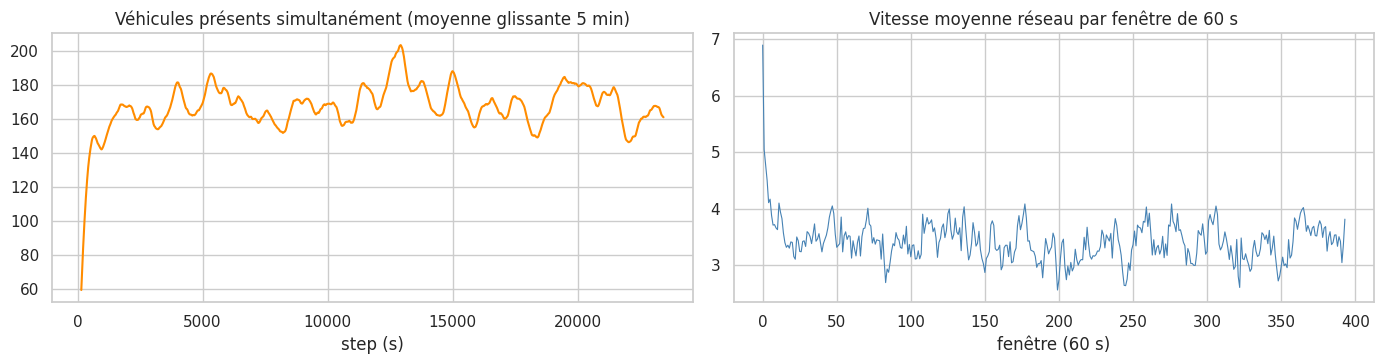

In [13]:
n_actifs = dt.groupby("step").size()
par_heure = dt.groupby(dt.step // 3600).agg(vitesse_moy=("speed", "mean"), n_lignes=("speed", "size"),
                                            p_arret=("speed", lambda s: (s < 0.1).mean()))
par_heure["vehicules_actifs_moy"] = n_actifs.groupby(n_actifs.index // 3600).mean()
print(par_heure.round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
n_actifs.rolling(300, center=True).mean().plot(ax=ax[0], color="darkorange")
ax[0].set_title("Véhicules présents simultanément (moyenne glissante 5 min)"); ax[0].set_xlabel("step (s)")
vit_t = dt.groupby(dt.step // WINDOW)["speed"].mean()
vit_t.plot(ax=ax[1], color="steelblue", lw=0.8)
ax[1].set_title(f"Vitesse moyenne réseau par fenêtre de {WINDOW} s"); ax[1].set_xlabel(f"fenêtre ({WINDOW} s)")
plt.tight_layout(); plt.show()

**Observation.** Le réseau part **vide** : pendant les 10 premières minutes environ, le nombre de véhicules monte de 60 à 165 et la vitesse moyenne est artificiellement élevée (route libre). Cette **phase de montée en charge** n'est pas représentative : on l'exclura de la modélisation (`WARMUP_S`, section 7). Ensuite, le nombre de véhicules oscille autour de 150 à 200 : le trafic est **globalement stationnaire** (pas de pointe nette) tandis que les véhicules entrent et sortent en permanence. La variation d'une minute à l'autre vient donc surtout de la **géographie** (où sont les véhicules) et des **cycles locaux** (feux, files), plus que d'une tendance globale. Cela justifie une variable de contexte « réseau entier » et des variables **spatiales**.

### 4.4 Véhicules et voies

Durée de présence d'un véhicule (secondes) :
count    9863.0
mean      397.6
std       281.5
min         1.0
25%       209.0
50%       324.0
75%       498.0
max      2953.0

Les 20 voies les plus fréquentées concentrent 24.0 % des observations (sur 2,482 voies)


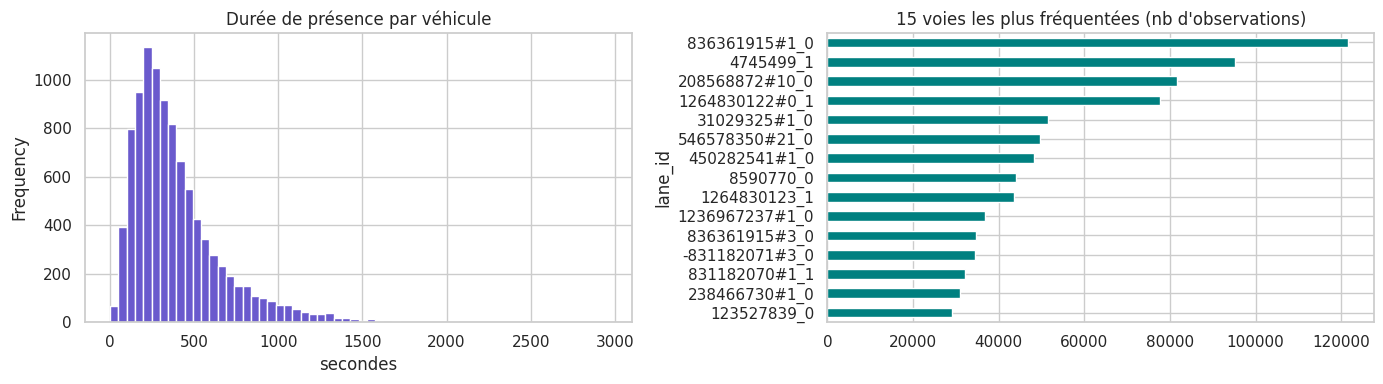

In [14]:
longueur = dt.groupby("id", observed=True).size()
print("Durée de présence d'un véhicule (secondes) :"); print(longueur.describe().round(1).to_string())

top_voies = dt.lane_id.value_counts().head(15)
part_top20 = dt.lane_id.value_counts().head(20).sum() / len(dt)
print(f"\nLes 20 voies les plus fréquentées concentrent {100*part_top20:.1f} % des observations (sur {dt.lane_id.nunique():,} voies)")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
longueur.plot.hist(bins=60, ax=ax[0], color="slateblue"); ax[0].set_title("Durée de présence par véhicule"); ax[0].set_xlabel("secondes")
top_voies.sort_values().plot.barh(ax=ax[1], color="teal"); ax[1].set_title("15 voies les plus fréquentées (nb d'observations)")
plt.tight_layout(); plt.show()

**Observation.** Les durées de présence sont très inégales (quelques secondes à près d'une heure) : un véhicule qui reste longtemps bloqué pèse beaucoup dans les statistiques. Les 20 voies les plus fréquentées (sur 2 482) concentrent à elles seules 24 % des observations : ce sont des axes très chargés ou des zones d'attente (probablement des goulots d'étranglement).

### 4.5 Structure spatiale : où roulent les véhicules, et à quelle vitesse ?

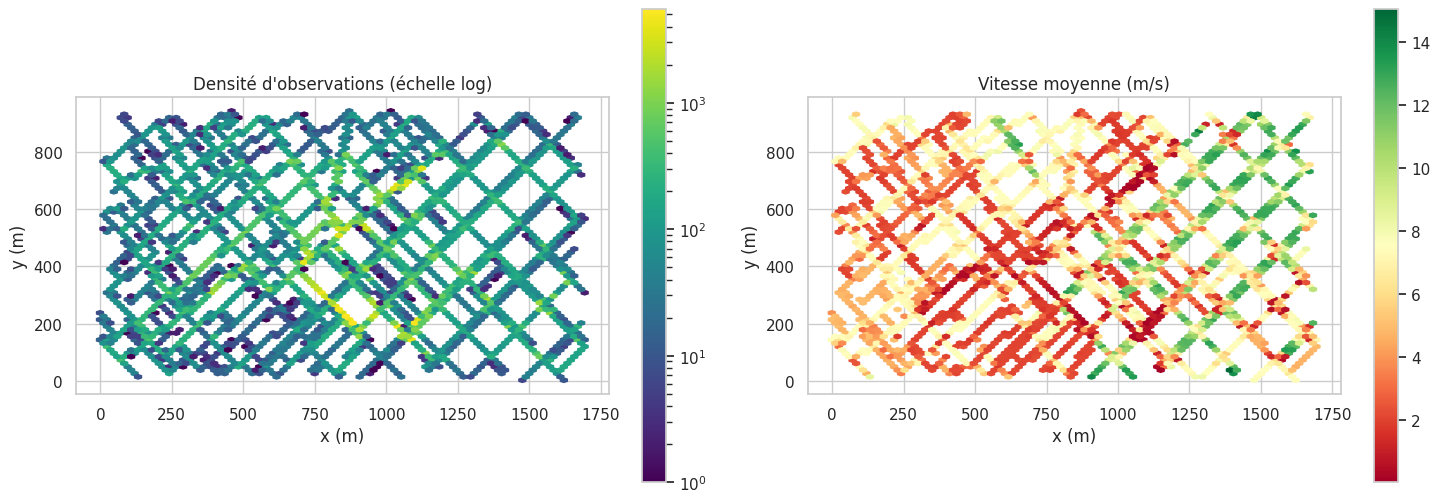

In [15]:
ech = dt.sample(500_000, random_state=SEED)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
h1 = ax[0].hexbin(ech.x, ech.y, gridsize=70, bins="log", cmap="viridis")
ax[0].set_title("Densité d'observations (échelle log)"); plt.colorbar(h1, ax=ax[0])
h2 = ax[1].hexbin(ech.x, ech.y, C=ech.speed, reduce_C_function=np.mean, gridsize=70, cmap="RdYlGn", mincnt=5)
ax[1].set_title("Vitesse moyenne (m/s)"); plt.colorbar(h2, ax=ax[1])
for a in ax: a.set_xlabel("x (m)"); a.set_ylabel("y (m)"); a.set_aspect("equal")
plt.tight_layout(); plt.show()

**Observation.** Le réseau est un **damier incliné à 45°** (deux familles de routes orthogonales). Quelques axes du centre (x entre 700 et 1 100 m) concentrent le plus d'observations. La vitesse varie fortement d'une zone à l'autre : la partie **est** (x > 1 200 m) est rapide (10 à 14 m/s en moyenne), alors que le **centre et l'ouest** sont lents, avec des poches à vitesse moyenne proche de 0 (files d'attente). La position est donc une information essentielle : elle sera conservée sous forme de **cellules de grille** (section 6) et de coordonnées de cellule.

### 4.6 Direction (`angle`) et type de voie

Observations dans une intersection (voie ':...') : 14.4 %
              mean  median    count
intersection                       
False         3.12    0.49  3356343
True          5.13    5.09   565433


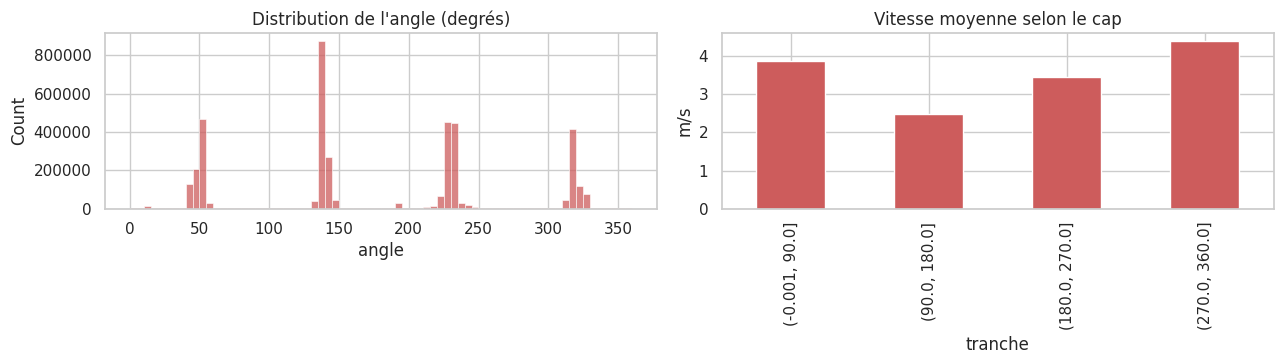

In [16]:
lane_str = pd.Series(dt.lane_id.cat.categories.astype(str))
interne  = lane_str.str.startswith(":").values
dt_int   = interne[dt.lane_id.cat.codes.values]
print(f"Observations dans une intersection (voie ':...') : {100*dt_int.mean():.1f} %")
print(dt.assign(intersection=dt_int).groupby("intersection")["speed"].agg(["mean", "median", "count"]).round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
sns.histplot(dt.angle, bins=72, ax=ax[0], color="indianred"); ax[0].set_title("Distribution de l'angle (degrés)")
dt.assign(tranche=pd.cut(dt.angle, [0, 90, 180, 270, 360], include_lowest=True)).groupby("tranche", observed=True)["speed"].mean().plot.bar(ax=ax[1], color="indianred")
ax[1].set_title("Vitesse moyenne selon le cap"); ax[1].set_ylabel("m/s")
plt.tight_layout(); plt.show()
del dt_int

**Observation.** Les caps se regroupent en **quatre directions** (environ 50°, 140°, 230° et 320°) : ce sont les quatre sens de circulation du damier. La vitesse moyenne dépend du sens (2,5 m/s pour les caps 90-180°, 4,4 m/s pour 270-360°), ce qui reflète la géographie du réseau. L'angle est de plus une grandeur **circulaire** : 359° et 1° sont presque identiques. Le donner tel quel à un modèle serait trompeur, on le remplacera par `sin(angle)` et `cos(angle)`. Contrairement à ce qu'on pourrait croire, les véhicules **à l'intérieur** des intersections roulent plus vite (5,1 m/s en moyenne) que sur les autres voies (3,1 m/s ; médiane 0,5 m/s) : les files d'attente se forment **en amont**, sur les voies d'approche, pas dans l'intersection elle-même. La part de véhicules en intersection (`p_internal`) est conservée comme variable ; son utilité sera mesurée par les modèles.

### 4.7 Corrélations et significativité

Avec presque 4 millions de lignes, **toute** corrélation, même minuscule, est « statistiquement significative » (p-value proche de 0). Il faut donc regarder la **taille** de la corrélation, pas seulement la p-value. On teste sur un échantillon de 100 000 lignes.

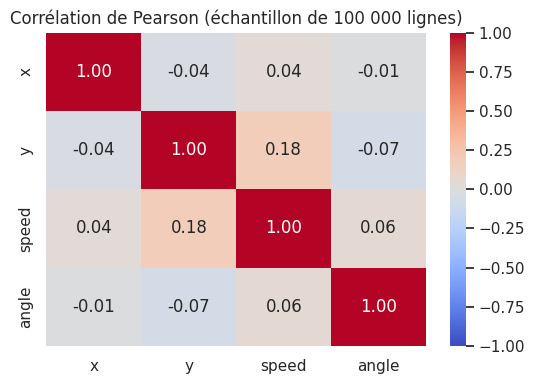

p-values associées :
             x         y    speed     angle
x      0.0e+00   9.9e-31  1.1e-31   4.4e-05
y      9.9e-31   0.0e+00  0.0e+00  2.9e-100
speed  1.1e-31   0.0e+00  0.0e+00   8.9e-72
angle  4.4e-05  2.9e-100  8.9e-72   0.0e+00
Spearman (speed vs autres) : {'x': -0.065, 'y': 0.201, 'angle': 0.055}


In [17]:
ech2 = dt.sample(100_000, random_state=SEED)
cols = ["x", "y", "speed", "angle"]
corr = ech2[cols].corr()
pv = pd.DataFrame({a: {b: stats.pearsonr(ech2[a], ech2[b])[1] for b in cols} for a in cols})

fig, ax = plt.subplots(figsize=(5.5, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax); ax.set_title("Corrélation de Pearson (échantillon de 100 000 lignes)")
plt.tight_layout(); plt.show()
print("p-values associées :"); print(pv.map(lambda p: f"{p:.1e}").to_string())

# Corrélation de rang (Spearman) : robuste aux relations non linéaires et aux valeurs extrêmes
print("Spearman (speed vs autres) :", {c: round(float(stats.spearmanr(ech2.speed, ech2[c])[0]), 3) for c in ["x", "y", "angle"]})

**Observation.** Les corrélations entre `speed` et les coordonnées ou l'angle sont **faibles** (|ρ| de Spearman ≤ 0,2) : la vitesse ne se lit pas directement dans la position brute. La relation est **non linéaire et locale** (telle zone est lente, telle autre rapide), ce qu'une corrélation linéaire globale ne capture pas. C'est une raison de plus pour préférer des modèles non linéaires (arbres, ANN) et des variables d'agrégation locales.

### 4.8 Synthèse des problèmes détectés

- Pas de valeur manquante ni de doublon dans le fichier brut ; `type` est constante.
- Quelques sauts de position impossibles (téléportations) : à supprimer.
- Vitesse à forte masse en zéro (véhicules à l'arrêt) : à représenter par `p_stopped`.
- `angle` circulaire : à encoder avec sin/cos.
- Trafic très concentré sur quelques voies et zones : la dimension spatiale est essentielle.
- Les identifiants (`id`) ne doivent pas être utilisés comme variables explicatives.

## 5. Nettoyage : la fonction `nettoyer(df)`

Les opérations sont appliquées **dans un ordre précis** (comme dans le TP d'exploration) :

1. tri par véhicule et par temps ;
2. suppression des sauts de position impossibles ;
3. suppression des colonnes constantes (`type`) ;
4. variables dérivées au niveau du véhicule : voie (route, numéro de voie, intersection ou non), accélération, arrêt, freinage brusque, `sin`/`cos` de l'angle.

Cette fonction n'utilise **aucune statistique du jeu entier** (seulement des différences entre deux lignes d'un même véhicule) : elle peut être appliquée avant le découpage sans fuite.

In [18]:
def nettoyer(df, v_max_impl=V_MAX_IMPL, hard_brake=HARD_BRAKE):
    # 1. tri
    df = df.sort_values(["id", "step"], ignore_index=True)

    # 2. sauts de position impossibles (artefacts de simulation)
    g = df.groupby("id", observed=True)
    v_impl = np.hypot(g["x"].diff(), g["y"].diff()) / g["step"].diff()
    n_avant = len(df)
    df = df.loc[~(v_impl > v_max_impl)].reset_index(drop=True)
    n_sup = n_avant - len(df)

    # 3. colonnes constantes
    constantes = [c for c in df.columns if df[c].nunique() == 1]
    df = df.drop(columns=constantes)

    # 4a. voie : route, numéro de voie, intersection (calculé sur les catégories, puis propagé)
    cats = pd.Series(df["lane_id"].cat.categories.astype(str))
    parts = cats.str.rsplit("_", n=1)
    route_of  = parts.str[0].values
    idx_of    = pd.to_numeric(parts.str[1], errors="coerce").fillna(0).astype("int8").values
    inter_of  = cats.str.startswith(":").values
    codes = df["lane_id"].cat.codes.values
    df["edge"]        = pd.Categorical(route_of[codes])
    df["lane_idx"]    = idx_of[codes]
    df["is_internal"] = inter_of[codes].astype("float32")

    # 4b. dynamique : accélération (m/s², pas de 1 s), arrêt, freinage brusque
    g = df.groupby("id", observed=True)
    acc = g["speed"].diff().where(g["step"].diff() == 1)
    df["acc"]        = acc.astype("float32")
    df["acc_abs"]    = df["acc"].abs()
    df["hard_brake"] = (df["acc"] < hard_brake).astype("float32")
    df["stopped"]    = (df["speed"] < 0.1).astype("float32")

    # 4c. angle circulaire -> sin / cos
    rad = np.deg2rad(df["angle"].astype("float32"))
    df["sin_a"] = np.sin(rad).astype("float32")
    df["cos_a"] = np.cos(rad).astype("float32")

    print(f"nettoyer : {n_sup} lignes supprimées (sauts impossibles), colonnes constantes retirées : {constantes}")
    return df

dt_clean = nettoyer(dt)
n_brut, n_propre = len(dt), len(dt_clean)
del dt
print(f"{n_brut:,} -> {n_propre:,} lignes")
dt_clean.head()

nettoyer : 63 lignes supprimées (sauts impossibles), colonnes constantes retirées : ['type']
3,921,776 -> 3,921,713 lignes


,step,id,x,y,speed,angle,lane_id,edge,lane_idx,is_internal,acc,acc_abs,hard_brake,stopped,sin_a,cos_a
0,0,veh0,470.490936,722.513794,0.000000,323.006775,288595616_0,288595616,0,0.0,NaN,NaN,0.0,1.0,-0.601721,0.798707
1,1,veh0,469.352539,724.024841,1.891703,323.006775,288595616_0,288595616,0,0.0,1.891703,1.891703,0.0,0.0,-0.601721,0.798707
2,2,veh0,467.735626,726.171082,2.686898,323.006775,288595616_0,288595616,0,0.0,0.795195,0.795195,0.0,0.0,-0.601721,0.798707
3,3,veh0,466.729248,727.506958,1.672368,323.006775,288595616_0,288595616,0,0.0,-1.014530,1.014530,0.0,0.0,-0.601721,0.798707
4,4,veh0,465.683472,728.895081,1.737784,323.006775,288595616_0,288595616,0,0.0,0.065416,0.065416,0.0,0.0,-0.601721,0.798707


In [19]:
# Contrôle de l'accélération après nettoyage : les valeurs extrêmes ont-elles disparu ?
print(dt_clean["acc"].describe().round(2).to_string())
print(f"\nFreinages brusques (< {HARD_BRAKE} m/s²) : {100*dt_clean.hard_brake.mean():.2f} % des observations")
print(f"Accélération max = {dt_clean.acc.max():.1f} m/s², décélération max = {dt_clean.acc.min():.1f} m/s²")
n_extr = int((dt_clean.acc.abs() > 9.5).sum())
print(f"|accélération| > 9,5 m/s² : {n_extr} observations sur {len(dt_clean):,} ({100*n_extr/len(dt_clean):.5f} %) -> conservées, trop rares pour peser ; "
      f"la décélération d'urgence est bornée à -9 m/s² par le simulateur")

count    3911746.00
mean           0.02
std            1.08
min           -9.00
25%           -0.09
50%            0.00
75%            0.23
max           13.89

Freinages brusques (< -3.0 m/s²) : 3.07 % des observations
Accélération max = 13.9 m/s², décélération max = -9.0 m/s²
|accélération| > 9,5 m/s² : 4 observations sur 3,921,713 (0.00010 %) -> conservées, trop rares pour peser ; la décélération d'urgence est bornée à -9 m/s² par le simulateur


## 6. Feature Engineering : des trajectoires aux observations « cellule × fenêtre »

**Principe.** Pour chaque cellule de 100 m et chaque fenêtre de 60 s, on résume les véhicules présents :

| Famille | Variables |
|---|---|
| Flux / densité | `n_veh` (véhicules distincts), `n_obs` (véhicule-secondes) |
| Vitesse | moyenne, écart-type, min, max, `p_stopped` (part à l'arrêt) |
| Dynamique | `acc_abs_mean`, `p_hard_brake` |
| Direction | `sin_mean`, `cos_mean` (moyennes de sin/cos du cap) |
| Contexte routier | `p_internal` (part en intersection), `lane_idx_max`, `n_lanes`, `n_edges` |
| Position | `cell_x`, `cell_y` (centre de la cellule) |
| **Historique** (passé uniquement) | valeurs aux fenêtres `t-1, t-2, t-3` et moyennes glissantes sur 3 fenêtres |
| **Voisinage** | vitesse et nombre de véhicules des 8 cellules voisines |
| **Réseau** | vitesse moyenne et nombre de véhicules sur tout le réseau à la même fenêtre |

Toutes ces variables à la fenêtre `t` n'utilisent que des informations disponibles à la fin de la fenêtre `t`. Les cibles sont celles de la fenêtre `t+1`.

In [20]:
def agreger(df, cell=CELL, win=WINDOW):
    """Résume les trajectoires par (fenêtre, cellule). Retourne un tableau complet fenêtres x grille."""
    x0, y0 = float(df.x.min()), float(df.y.min())
    d = pd.DataFrame({
        "w":  (df.step // win).astype("int32"),
        "cx": ((df.x - x0) // cell).astype("int16"),
        "cy": ((df.y - y0) // cell).astype("int16"),
        "id": df.id, "lane_id": df.lane_id, "edge": df.edge, "speed": df.speed,
        "stopped": df.stopped, "acc_abs": df.acc_abs, "hard_brake": df.hard_brake,
        "sin_a": df.sin_a, "cos_a": df.cos_a, "is_internal": df.is_internal, "lane_idx": df.lane_idx})
    agg = d.groupby(["w", "cy", "cx"], observed=True).agg(
        n_obs=("id", "size"), n_veh=("id", "nunique"),
        speed_mean=("speed", "mean"), speed_std=("speed", "std"),
        speed_min=("speed", "min"), speed_max=("speed", "max"),
        p_stopped=("stopped", "mean"), acc_abs_mean=("acc_abs", "mean"), p_hard_brake=("hard_brake", "mean"),
        sin_mean=("sin_a", "mean"), cos_mean=("cos_a", "mean"),
        p_internal=("is_internal", "mean"), lane_idx_max=("lane_idx", "max"),
        n_lanes=("lane_id", "nunique"), n_edges=("edge", "nunique"))
    W, NY, NX = int(d.w.max()) + 1, int(d.cy.max()) + 1, int(d.cx.max()) + 1
    idx = pd.MultiIndex.from_product([range(W), range(NY), range(NX)], names=["w", "cy", "cx"])
    full = agg.reindex(idx)
    compteurs = ["n_obs", "n_veh", "n_lanes", "n_edges"]
    full[compteurs] = full[compteurs].fillna(0)          # aucune observation = 0 véhicule (et non une valeur inconnue)
    full = full.reset_index()
    full["cell_id"] = full.cy * NX + full.cx
    full["cell_x"]  = x0 + (full.cx + 0.5) * cell
    full["cell_y"]  = y0 + (full.cy + 0.5) * cell
    return full, (W, NY, NX)

grille, (W, NY, NX) = agreger(dt_clean)
print(f"Grille : {NX} x {NY} cellules de {CELL} m, {W} fenêtres de {WINDOW} s -> {len(grille):,} lignes (cellule x fenêtre)")
print(f"Cellules x fenêtres jamais occupées : {100*(grille.n_obs == 0).mean():.1f} %")
print(f"Nombre de véhicules par cellule occupée : médiane {grille.loc[grille.n_veh > 0, 'n_veh'].median():.0f}, "
      f"moyenne {grille.loc[grille.n_veh > 0, 'n_veh'].mean():.1f}, max {grille.n_veh.max():.0f}")
grille.head()

Grille : 17 x 10 cellules de 100 m, 394 fenêtres de 60 s -> 66,980 lignes (cellule x fenêtre)
Cellules x fenêtres jamais occupées : 18.4 %
Nombre de véhicules par cellule occupée : médiane 4, moyenne 4.5, max 33


,w,cy,cx,n_obs,n_veh,speed_mean,speed_std,speed_min,speed_max,p_stopped,acc_abs_mean,p_hard_brake,sin_mean,cos_mean,p_internal,lane_idx_max,n_lanes,n_edges,cell_id,cell_x,cell_y
0,0,0,0,20.0,1.0,3.845545,2.876868,0.000214,6.877575,0.25,0.867743,0.0,-0.661007,0.750365,0.100000,1.0,3.0,3.0,0,48.661266,50.183826
1,0,0,1,6.0,1.0,6.395185,0.453971,5.663432,6.922230,0.00,0.500955,0.0,-0.654283,0.756104,0.333333,1.0,3.0,3.0,1,148.661266,50.183826
2,0,0,2,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,2,248.661266,50.183826
3,0,0,3,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,3,348.661266,50.183826
4,0,0,4,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,4,448.661266,50.183826


**Valeurs manquantes structurelles.** Lorsqu'une cellule est vide pendant une fenêtre, `n_veh = n_obs = 0` (c'est une vraie information : *zéro véhicule*), mais la **vitesse moyenne n'existe pas** (`NaN`). Ces `NaN` ne sont ni au hasard ni des erreurs : ils signifient « rien à mesurer ». On ne les imputera donc pas avec la moyenne de tout le jeu ; l'imputation (section 8) utilisera une statistique du **train** et l'indicateur `n_obs = 0` reste disponible pour le modèle.

In [21]:
pct_nan = grille.isna().mean().mul(100).round(1)
print(pct_nan[pct_nan > 0].sort_values(ascending=False).to_string())

speed_std       19.9
acc_abs_mean    18.5
speed_mean      18.4
speed_min       18.4
speed_max       18.4
p_stopped       18.4
p_hard_brake    18.4
sin_mean        18.4
cos_mean        18.4
p_internal      18.4
lane_idx_max    18.4


In [22]:
# ---------- Variables de réseau, de voisinage et d'historique ----------
grille = grille.sort_values(["w", "cy", "cx"], ignore_index=True)

# Réseau entier à la même fenêtre
grille["speed_sum"] = grille.speed_mean.fillna(0) * grille.n_obs
net = grille.groupby("w").agg(net_n_veh=("n_veh", "sum"), net_obs=("n_obs", "sum"), net_speed_sum=("speed_sum", "sum"))
net["net_speed"] = net.net_speed_sum / net.net_obs
grille = grille.merge(net[["net_n_veh", "net_speed"]], left_on="w", right_index=True, how="left")

# Voisinage : somme sur les 8 cellules voisines (même fenêtre)
def somme_voisins(col):
    a = grille[col].to_numpy(dtype="float64").reshape(W, NY, NX)
    p = np.pad(a, ((0, 0), (1, 1), (1, 1)))
    s = sum(p[:, 1 + dy:1 + dy + NY, 1 + dx:1 + dx + NX] for dy in (-1, 0, 1) for dx in (-1, 0, 1) if (dy, dx) != (0, 0))
    return s.reshape(-1)

grille["nb_n_obs"] = somme_voisins("n_obs")
grille["nb_n_veh"] = somme_voisins("n_veh")
grille["nb_speed"] = np.where(grille.nb_n_obs > 0, somme_voisins("speed_sum") / grille.nb_n_obs.replace(0, np.nan), np.nan)

# Historique : décalages du passé UNIQUEMENT (shift positif) ; la cellule est le groupe
cell_g = grille.groupby("cell_id")
for k in range(1, N_LAGS + 1):
    grille[f"n_veh_lag{k}"]     = cell_g["n_veh"].shift(k)
    grille[f"n_obs_lag{k}"]     = cell_g["n_obs"].shift(k)
    grille[f"speed_lag{k}"]     = cell_g["speed_mean"].shift(k)
    grille[f"p_stopped_lag{k}"] = cell_g["p_stopped"].shift(k)
grille["speed_sum_lag1"] = cell_g["speed_sum"].shift(1)
grille["speed_sum_lag2"] = cell_g["speed_sum"].shift(2)

# Moyennes glissantes sur t, t-1, t-2 (vitesse pondérée par le nombre d'observations)
obs3 = grille.n_obs + grille.n_obs_lag1 + grille.n_obs_lag2
grille["n_veh_roll3"] = (grille.n_veh + grille.n_veh_lag1 + grille.n_veh_lag2) / 3
grille["speed_roll3"] = np.where(obs3 > 0, (grille.speed_sum + grille.speed_sum_lag1 + grille.speed_sum_lag2) / obs3.replace(0, np.nan), np.nan)

# Tendance : le nombre de véhicules augmente-t-il ?
grille["n_veh_trend"] = grille.n_veh - grille.n_veh_lag1

# ---------- Cibles : fenêtre t+1 ----------
grille["speed_next"] = cell_g["speed_mean"].shift(-1)
grille["n_veh_next"] = cell_g["n_veh"].shift(-1)
grille["w_cible"]    = grille.w + 1

print(f"{grille.shape[1]} colonnes après feature engineering")

47 colonnes après feature engineering


**Contrôle anti-fuite.** Toutes les variables d'historique sont des `shift(k)` avec `k > 0` (valeurs *passées*), et les cibles sont des `shift(-1)` (valeur *future*). On vérifie ci-dessous qu'aucune variable explicative n'est identique à une cible, et que la cible d'une ligne est bien la valeur de la fenêtre suivante.

In [23]:
# Vérification 1 : speed_next(w) == speed_mean(w+1) pour la même cellule
a = grille[["cell_id", "w", "speed_mean", "n_veh"]].copy(); a["w"] -= 1
chk = grille[["cell_id", "w", "speed_next", "n_veh_next"]].merge(a, on=["cell_id", "w"], how="inner")
ok_speed = np.allclose(chk.speed_next.fillna(-1), chk.speed_mean.fillna(-1))
ok_veh   = np.allclose(chk.n_veh_next, chk.n_veh)
print("Cible = valeur de la fenêtre suivante :", ok_speed and ok_veh)

# Vérification 2 : l'historique ne contient que du passé
ex = grille[grille.cell_id == grille.loc[grille.n_veh.idxmax(), "cell_id"]].set_index("w")
assert (ex.n_veh_lag1.iloc[1:].values == ex.n_veh.iloc[:-1].values).all()
print("n_veh_lag1(w) == n_veh(w-1) : OK")
del a, chk, ex

Cible = valeur de la fenêtre suivante : True
n_veh_lag1(w) == n_veh(w-1) : OK


## 7. Jeu supervisé, cibles et découpage train / validation / test

### 7.1 Lignes retenues

- On enlève les premières fenêtres : la **phase de montée en charge** du réseau (`WARMUP_S` = 10 minutes, section 4.3), qui couvre aussi les `N_LAGS` fenêtres sans historique complet. On enlève aussi la dernière fenêtre (pas de cible).
- On garde les lignes qui ont eu de l'**activité récente** (véhicules dans la cellule, dans ses voisines, ou aux fenêtres `t-1, t-2`). Cette règle n'utilise que le passé : elle est applicable en production. Les lignes sans aucune activité récente (environ 1 % ici) sont donc exclues, sans regarder le futur.
- `speed_next` est **indéfinie** quand la cellule est vide à `t+1` : ces lignes seront écartées pour la régression de la vitesse (on prédit la vitesse *quand il y a des véhicules*), mais gardées pour la prédiction du flux (prédire « 0 véhicule » est utile).

In [24]:
w_debut = max(N_LAGS, WARMUP_S // WINDOW)
data = grille[(grille.w >= w_debut) & (grille.w < W - 1)].copy()
activite = data.n_obs + data.n_obs_lag1 + data.n_obs_lag2 + data.nb_n_obs
data = data[activite > 0].reset_index(drop=True)

print(f"Lignes : {len(data):,}  (sur {len(grille):,} cellules x fenêtres)")
print(f"speed_next non défini (cellule vide à t+1) : {100*data.speed_next.isna().mean():.1f} %")
print(f"n_veh_next == 0                           : {100*(data.n_veh_next == 0).mean():.1f} %")

Lignes : 64,863  (sur 66,980 cellules x fenêtres)
speed_next non défini (cellule vide à t+1) : 17.8 %
n_veh_next == 0                           : 17.8 %


### 7.2 Découpage **chronologique** (anti-fuite)

On découpe selon la fenêtre de la **cible** : 70 % des fenêtres pour l'entraînement, 15 % pour la validation, 15 % pour le test. Aucune ligne d'entraînement n'a donc de cible située dans la période de validation ou de test.

Les variables d'historique d'une ligne de validation peuvent regarder dans le passé (fenêtres d'entraînement) : c'est légitime, car au moment de la prédiction ce passé est connu.

Ensuite, **tout ce qui est « appris » sur les données** (seuils de classes, profil des cellules, imputation, normalisation, sélection de variables, PCA) est calculé **sur le train uniquement**, puis appliqué tel quel à la validation et au test.

In [25]:
T1 = int(TRAIN_FRAC * W)
T2 = int((TRAIN_FRAC + VAL_FRAC) * W)
data["split"] = np.select([data.w_cible <= T1, data.w_cible <= T2], ["train", "val"], default="test")

resume = data.groupby("split").agg(lignes=("w", "size"), w_min=("w_cible", "min"), w_max=("w_cible", "max"))
resume["minutes"] = resume.w_max - resume.w_min + 1
print(resume.loc[["train", "val", "test"]].to_string())

# Aucune cible d'entraînement ne tombe dans la période de val/test
assert data.loc[data.split == "train", "w_cible"].max() <= T1
assert data.loc[data.split == "val", "w_cible"].min() > T1
assert data.loc[data.split == "test", "w_cible"].min() > T2
print("\nChevauchement des périodes : aucun (vérifié)")

       lignes  w_min  w_max  minutes
split                               
train   44873     11    275      265
val      9990    276    334       59
test    10000    335    393       59

Chevauchement des périodes : aucun (vérifié)


### 7.3 Cible de classification `etat_next` (seuils appris sur le train)

On découpe la vitesse future en trois états aux **terciles du train** (33 % et 66 %). On obtient trois classes équilibrées, ce qui évite le piège de l'accuracy sur classes déséquilibrées vu en cours. Les seuils viennent du train seul : sinon, la définition même de la cible utiliserait de l'information du futur.

Seuils (train) : congestionné <= 3.93 m/s < ralenti <= 7.19 m/s < fluide
etat_next  congestionné  ralenti  fluide
split                                   
train              33.3     33.3    33.3
val                33.6     33.4    33.0
test               33.1     33.8    33.1

Asymétrie de n_veh_next : 1.54   |   asymétrie de speed_next : 0.47


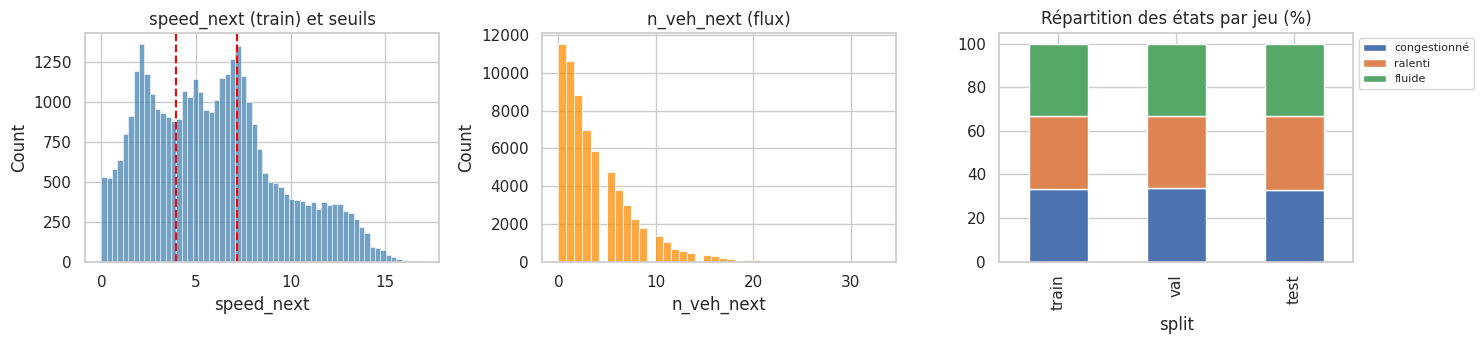

In [26]:
tr_speed = data.loc[(data.split == "train") & data.speed_next.notna(), "speed_next"]
SEUILS = tr_speed.quantile([1/3, 2/3]).values
ETATS  = ["congestionné", "ralenti", "fluide"]           # ordre explicite : du pire au meilleur

data["etat_next"] = pd.cut(data.speed_next, bins=[-np.inf, SEUILS[0], SEUILS[1], np.inf], labels=ETATS)
print(f"Seuils (train) : congestionné <= {SEUILS[0]:.2f} m/s < ralenti <= {SEUILS[1]:.2f} m/s < fluide")

rep = data.groupby("split")["etat_next"].value_counts(normalize=True).unstack().loc[["train", "val", "test"], ETATS]
print((100 * rep).round(1).to_string())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
sns.histplot(tr_speed, bins=60, ax=ax[0], color="steelblue"); ax[0].set_title("speed_next (train) et seuils")
for s in SEUILS: ax[0].axvline(s, color="red", ls="--")
sns.histplot(data.n_veh_next, bins=40, ax=ax[1], color="darkorange"); ax[1].set_title("n_veh_next (flux)")
print(f"\nAsymétrie de n_veh_next : {data.n_veh_next.skew():.2f}   |   asymétrie de speed_next : {data.speed_next.skew():.2f}")
(100 * rep).plot.bar(stacked=True, ax=ax[2]); ax[2].set_title("Répartition des états par jeu (%)"); ax[2].legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout(); plt.show()

**Observation.** Les trois états sont à peu près équilibrés dans le train (par construction) et restent proches dans la validation et le test : le trafic est **stationnaire**, donc les seuils appris sur le début de la simulation restent valables ensuite. Le flux `n_veh_next` est très asymétrique à droite (beaucoup de petites valeurs, quelques gros pics) : on gardera cette asymétrie en tête pour le choix des métriques (MAE, RMSE) dans la partie 2.

## 8. Imputation, encodage, sélection, normalisation, PCA

### 8.1 Profil historique des cellules (encodage de `cell_id`)

`cell_id` est une variable catégorielle à **170 modalités** (une par cellule). Un *one-hot* ajouterait 170 colonnes presque vides ; un *ordinal* inventerait un ordre qui n'existe pas. On utilise plutôt un **encodage par statistique** : chaque cellule est décrite par son comportement habituel (vitesse moyenne, activité, part d'arrêts), **calculé sur le train uniquement**. Une cellule jamais vue dans le train reçoit la valeur médiane (section 8.2).

Un léger biais subsiste : pour une ligne du train, la moyenne de sa cellule contient (parmi des centaines de fenêtres) sa propre cible. Avec environ 270 fenêtres par cellule, l'effet d'une seule ligne est faible ; le jeu de validation n'a pas ce biais et permettra de le vérifier.

In [27]:
tr = data[data.split == "train"]
profil = tr.groupby("cell_id").agg(cell_speed_mean=("speed_mean", "mean"),
                                   cell_obs_mean=("n_obs", "mean"),
                                   cell_stop_mean=("p_stopped", "mean"))
data = data.merge(profil, left_on="cell_id", right_index=True, how="left")
print(f"{len(profil)} cellules dans le train ; cellules du jeu complet absentes du train : {data.cell_id.nunique() - len(profil)}")
profil.describe().round(2)

170 cellules dans le train ; cellules du jeu complet absentes du train : 0


,cell_speed_mean,cell_obs_mean,cell_stop_mean
count,168.00,170.00,168.00
mean,5.91,59.45,0.15
std,2.90,82.84,0.21
min,0.68,0.00,0.00
25%,3.60,12.39,0.01
50%,5.81,34.16,0.04
75%,7.72,68.82,0.20
max,13.03,574.97,0.86


### 8.2 Valeurs manquantes (imputation)

Les `NaN` restants sont les vitesses et statistiques associées des fenêtres vides. Stratégie du cours (imputation par la **médiane**, robuste aux valeurs extrêmes), avec la médiane **ajustée sur le train** puis appliquée aux trois jeux. L'information « la cellule était vide » n'est pas perdue : elle est portée par `n_obs`, `n_veh` et leurs retards.

In [28]:
META    = ["w", "w_cible", "cell_id", "split"]
CIBLES  = ["speed_next", "n_veh_next", "etat_next"]
FEATS_0 = [c for c in data.columns if c not in META + CIBLES + ["cx", "cy", "speed_sum", "speed_sum_lag1", "speed_sum_lag2"]]
print(f"{len(FEATS_0)} variables candidates")

nan_train = data.loc[data.split == "train", FEATS_0].isna().mean().mul(100).round(1)
print("\n% de NaN dans le train, avant imputation :")
print(nan_train[nan_train > 0].sort_values(ascending=False).to_string())

imputer = SimpleImputer(strategy="median")
imputer.fit(data.loc[data.split == "train", FEATS_0])          # ajusté sur le TRAIN seul
X_all = pd.DataFrame(imputer.transform(data[FEATS_0]), columns=FEATS_0, index=data.index)
print("\nNaN restants :", int(X_all.isna().sum().sum()))

40 variables candidates

% de NaN dans le train, avant imputation :
speed_std          19.2
speed_lag3         17.7
p_stopped_lag3     17.7
acc_abs_mean       17.7
speed_mean         17.6
p_stopped          17.6
speed_max          17.6
speed_min          17.6
p_hard_brake       17.6
p_internal         17.6
lane_idx_max       17.6
sin_mean           17.6
cos_mean           17.6
p_stopped_lag2     17.6
speed_lag1         17.6
speed_lag2         17.6
p_stopped_lag1     17.6
speed_roll3         5.8
cell_speed_mean     1.1
cell_stop_mean      1.1
nb_speed            0.3

NaN restants : 0


### 8.3 Encodage de la cible de classification

Les trois états ont un **ordre naturel** (congestionné < ralenti < fluide). On utilise donc un `OrdinalEncoder` avec l'ordre explicite, car par défaut l'encodeur classerait par ordre alphabétique (`congestionné`, `fluide`, `ralenti`), ce qui serait faux.

In [29]:
enc = OrdinalEncoder(categories=[ETATS])
mask_c = data.etat_next.notna()
y_cls = pd.Series(np.nan, index=data.index)
y_cls[mask_c] = enc.fit_transform(data.loc[mask_c, ["etat_next"]].astype(str)).ravel()
print("Encodage :", {e: i for i, e in enumerate(ETATS)})
print(pd.crosstab(data.etat_next, y_cls, dropna=False).to_string())

Encodage : {'congestionné': 0, 'ralenti': 1, 'fluide': 2}
col_0           0.0    1.0    2.0
etat_next                        
NaN               0      0      0
congestionné  17767      0      0
ralenti           0  17816      0
fluide            0      0  17724


### 8.4 Sélection de variables (sur le train)

Trois filtres, tous calculés sur le **train**, pour la cible de vitesse :

1. **Variance quasi nulle** : une variable constante n'apprend rien.
2. **Redondance** : si deux variables ont une corrélation absolue > 0,95, on en garde une (le moins redondant est préférable pour les modèles linéaires et les ANN ; les arbres y sont moins sensibles).
3. **Pertinence** : classement par `f_regression` (lien linéaire) et `mutual_info_regression` (lien quelconque) avec `speed_next`. Pour la classification, test du **khi-deux** sur les variables mises à l'échelle [0, 1] (le khi-deux exige des valeurs positives).

In [30]:
tr_mask  = (data.split == "train").values
sp_mask  = tr_mask & data.speed_next.notna().values       # train avec cible de vitesse définie
Xtr      = X_all.loc[tr_mask]

# 1. variance
vt = VarianceThreshold(threshold=1e-8).fit(Xtr)
cst = [c for c, keep in zip(FEATS_0, vt.get_support()) if not keep]
print("1. Variables à variance quasi nulle :", cst or "aucune")

# 2. redondance
def filtre_correlation(X, seuil=0.95):
    c = X.corr().abs()
    haut = c.where(np.triu(np.ones(c.shape), k=1).astype(bool))
    return {col: haut.index[haut[col] > seuil].tolist() for col in haut.columns if (haut[col] > seuil).any()}

redondantes = filtre_correlation(Xtr.drop(columns=cst))
print("\n2. Variables redondantes (|r| > 0,95) -> avec quelles variables :")
for k, v in redondantes.items(): print(f"   {k:16s} ~ {v}")
a_supprimer = list(redondantes.keys())

FEATS = [c for c in FEATS_0 if c not in cst + a_supprimer]
print(f"\n=> {len(FEATS)} variables conservées sur {len(FEATS_0)} (retirées : {len(FEATS_0) - len(FEATS)})")

1. Variables à variance quasi nulle : aucune

2. Variables redondantes (|r| > 0,95) -> avec quelles variables :
   n_edges          ~ ['n_lanes']

=> 39 variables conservées sur 40 (retirées : 1)


                 f_regression  mutual_info      chi2  rang_moyen
cell_speed_mean     88525.910        0.793  2868.988       2.667
speed_roll3         59986.386        0.582  2014.537       4.000
cell_stop_mean      13995.853        0.515  3638.988       4.667
speed_mean          41855.394        0.476  1818.891       5.667
speed_lag1          34680.922        0.420  1613.662       6.667
p_stopped           11540.186        0.222  3946.439       7.333
speed_lag2          33224.514        0.395  1560.909       8.000
speed_lag3          32753.763        0.402  1545.471       8.333
p_stopped_lag1      10255.742        0.198  3697.756       8.333
speed_min           12986.847        0.224  2093.686       8.667
cell_obs_mean        8622.846        0.554  1270.687      10.000
p_stopped_lag2       9603.467        0.175  3478.153      10.667
p_stopped_lag3       9161.871        0.169  3350.720      11.667
nb_speed            13646.129        0.187   645.833      13.667
n_obs                7760

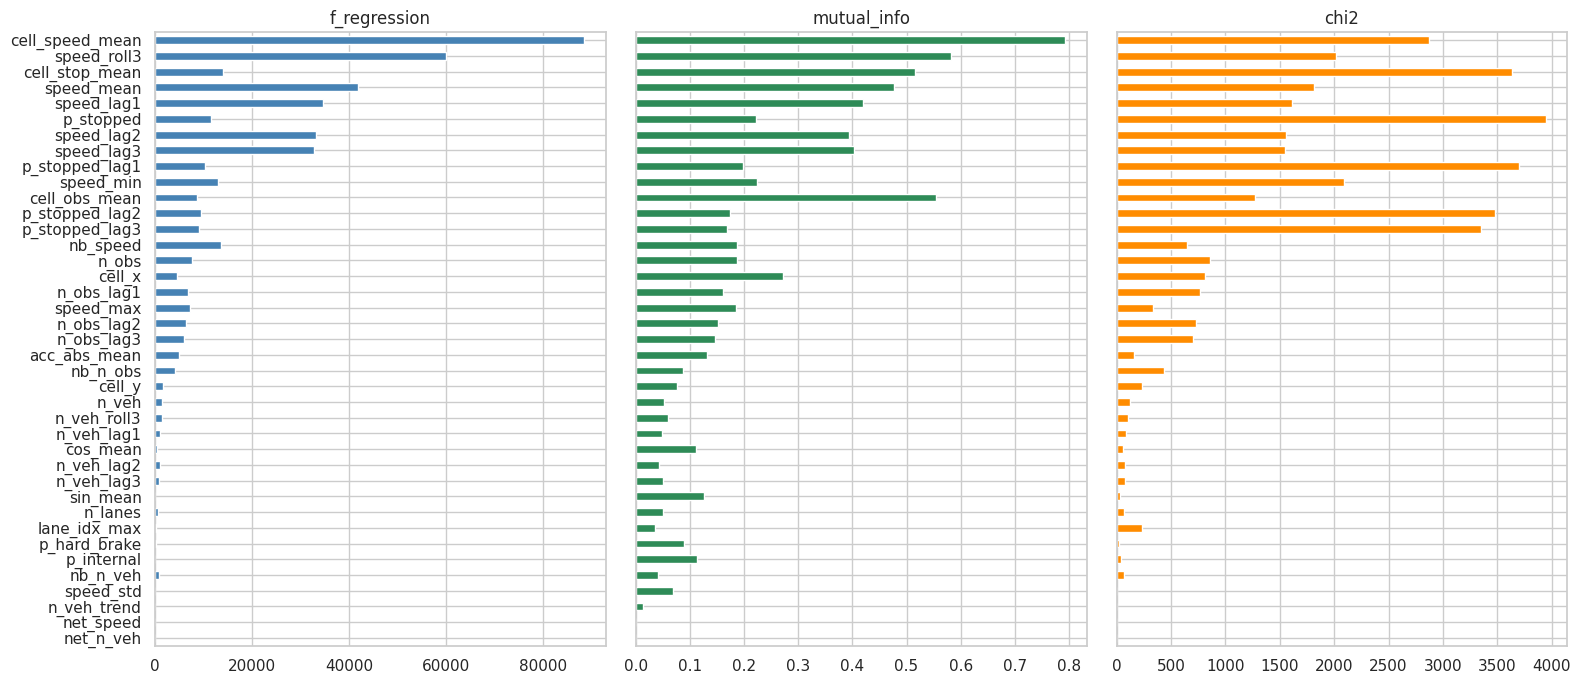

In [31]:
# 3. pertinence (train, cible vitesse définie)
Xs, ys = X_all.loc[sp_mask, FEATS], data.loc[sp_mask, "speed_next"]
f_sc, _ = f_regression(Xs, ys)
rng_idx = np.random.RandomState(SEED).choice(len(Xs), size=min(20_000, len(Xs)), replace=False)
mi_sc = mutual_info_regression(Xs.iloc[rng_idx], ys.iloc[rng_idx], random_state=SEED)

# khi-deux (classification) : variables mises à l'échelle [0, 1]
cl_mask = tr_mask & mask_c.values
Xc = MinMaxScaler().fit_transform(X_all.loc[cl_mask, FEATS])
chi_sc, chi_p = chi2(Xc, y_cls[cl_mask])

scores = pd.DataFrame({"f_regression": f_sc, "mutual_info": mi_sc, "chi2": chi_sc}, index=FEATS)
scores["rang_moyen"] = scores.rank(ascending=False).mean(axis=1)
scores = scores.sort_values("rang_moyen")
print(scores.round(3).head(15).to_string())

# Même question pour la cible de flux (toutes les lignes du train)
f_flux, _ = f_regression(X_all.loc[tr_mask, FEATS], data.loc[tr_mask, "n_veh_next"])
print("\nVariables les plus liées au flux futur n_veh_next (f_regression) :")
print(pd.Series(f_flux, index=FEATS).sort_values(ascending=False).head(6).round(0).to_string())

ordre = scores.index[::-1]          # même ordre (rang moyen) sur les trois graphiques
fig, ax = plt.subplots(1, 3, figsize=(16, 7), sharey=True)
for a, col, c in zip(ax, ["f_regression", "mutual_info", "chi2"], ["steelblue", "seagreen", "darkorange"]):
    scores.loc[ordre, col].plot.barh(ax=a, color=c); a.set_title(col)
plt.tight_layout(); plt.show()

**Lecture et décision.** Les variables les plus liées à la vitesse de la minute suivante sont, sans surprise, la **vitesse actuelle et passée** de la cellule et de son voisinage, la part d'arrêts et le profil historique de la cellule. Le **flux** futur (`n_veh_next`) est surtout lié au flux actuel et récent de la cellule (`n_veh_roll3`, `n_veh`, `n_veh_lag1`) et au flux de ses voisines (`nb_n_veh`).

On ne garde pas seulement le « top-k » : les arbres (partie 2) savent ignorer les variables peu utiles, et un score univarié ne voit pas les **interactions** (par exemple vitesse × densité). On conserve donc toutes les variables non redondantes (`FEATS`), et on utilisera `scores` pour justifier le choix dans le rapport et, si besoin, réduire la dimension pour l'ANN. Les variables `net_speed`, `net_n_veh` et `n_veh_trend` ont un score presque nul pour la vitesse : ce sont les premières candidates à retirer si un modèle sur-apprend, mais on les garde pour tester leur utilité sur le flux.

### 8.5 Transformation et normalisation

Deux versions du même jeu :
- **brute** (`X_*`) pour les arbres, forêts, boosting : ils ne dépendent pas de l'échelle des variables ;
- **normalisée** (`Xs_*`) pour l'ANN : transformation `log(1+x)` des variables de comptage très asymétriques, puis **standardisation** (`StandardScaler`) ajustée sur le train.

Asymétrie (skew) > 2 et valeurs >= 0 -> transformation log(1+x) :
n_obs            3.98
p_hard_brake     3.50
n_obs_lag1       3.99
n_obs_lag2       3.99
n_obs_lag3       3.99
cell_obs_mean    3.13


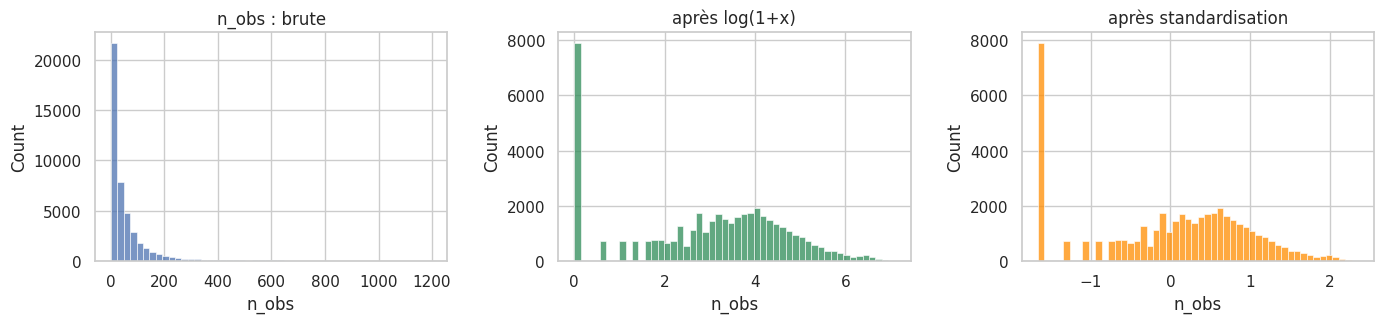


Vérification (train) : moyenne ~ 0 et écart-type ~ 1
     mean  std
min  -0.0  1.0
max   0.0  1.0
Validation (non nulle, c'est normal : statistiques du train) : 0.012


In [32]:
skew_tr = Xtr[FEATS].skew().sort_values(ascending=False)
LOG_COLS = [c for c in FEATS if skew_tr[c] > 2 and X_all[c].min() >= 0]
print("Asymétrie (skew) > 2 et valeurs >= 0 -> transformation log(1+x) :")
print(skew_tr[LOG_COLS].round(2).to_string())

def transformer(X):
    X = X[FEATS].copy()
    X[LOG_COLS] = np.log1p(X[LOG_COLS])
    return X

scaler = StandardScaler().fit(transformer(Xtr))                 # ajusté sur le TRAIN
Xs_all = pd.DataFrame(scaler.transform(transformer(X_all)), columns=FEATS, index=X_all.index)

# Effet visuel sur une variable
c = LOG_COLS[0]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
sns.histplot(Xtr[c], bins=50, ax=ax[0]); ax[0].set_title(f"{c} : brute")
sns.histplot(np.log1p(Xtr[c]), bins=50, ax=ax[1], color="seagreen"); ax[1].set_title("après log(1+x)")
sns.histplot(Xs_all.loc[tr_mask, c], bins=50, ax=ax[2], color="darkorange"); ax[2].set_title("après standardisation")
plt.tight_layout(); plt.show()

print("\nVérification (train) : moyenne ~ 0 et écart-type ~ 1")
print(Xs_all.loc[tr_mask].agg(["mean", "std"]).T.describe().loc[["min", "max"]].round(3).to_string())
print("Validation (non nulle, c'est normal : statistiques du train) :", Xs_all.loc[(data.split == 'val').values].mean().abs().mean().round(3))

### 8.6 Réduction de dimension (PCA)

La PCA (analyse en composantes principales) sert ici à **mesurer la redondance** entre variables et à visualiser les classes en 2D. Elle est ajustée sur le train normalisé. On ne l'impose pas aux modèles : les composantes sont difficiles à interpréter et les arbres n'en ont pas besoin. Elle reste disponible pour l'ANN.

23 composantes sur 39 expliquent 95 % de la variance ; 11 expliquent 80 %


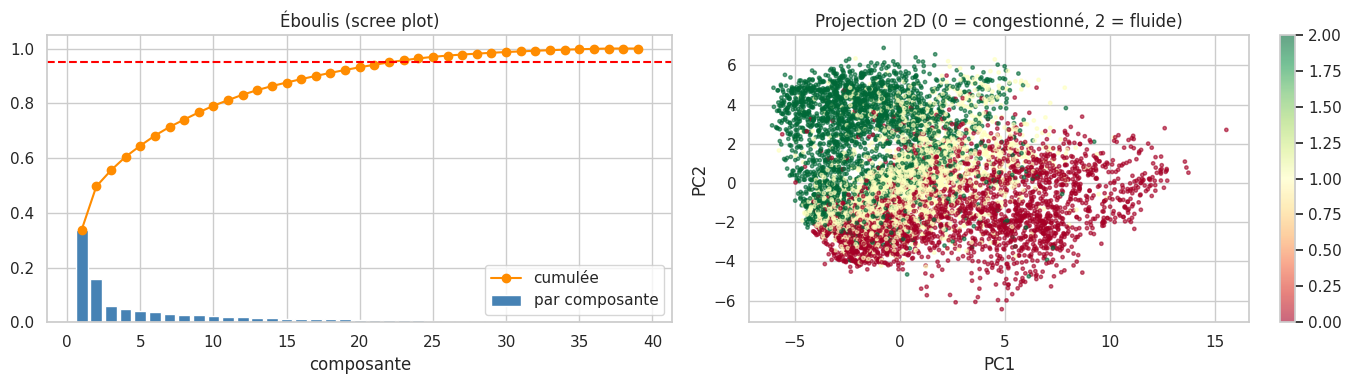

Variables qui pèsent le plus sur PC1 :
cell_obs_mean     0.24
n_veh_roll3       0.23
cell_stop_mean    0.23
n_obs             0.22
n_obs_lag1        0.22
p_stopped_lag1    0.21
Variables qui pèsent le plus sur PC2 :
speed_max          0.32
cell_speed_mean    0.29
speed_roll3        0.29
speed_mean         0.28
speed_lag2         0.26
speed_lag1         0.26
Variance expliquée par PC1 + PC2 : 50 %


In [33]:
pca = PCA(random_state=SEED).fit(Xs_all.loc[tr_mask])
cumul = np.cumsum(pca.explained_variance_ratio_)
n95 = int(np.argmax(cumul >= 0.95) + 1)
print(f"{n95} composantes sur {len(FEATS)} expliquent 95 % de la variance ; {int(np.argmax(cumul >= 0.80) + 1)} expliquent 80 %")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(range(1, len(cumul) + 1), pca.explained_variance_ratio_, color="steelblue", label="par composante")
ax[0].plot(range(1, len(cumul) + 1), cumul, "o-", color="darkorange", label="cumulée")
ax[0].axhline(0.95, color="red", ls="--"); ax[0].set_xlabel("composante"); ax[0].set_title("Éboulis (scree plot)"); ax[0].legend()

pts = np.random.RandomState(SEED).choice(np.where(cl_mask)[0], size=min(8000, cl_mask.sum()), replace=False)
Z = pca.transform(Xs_all.iloc[pts])[:, :2]
sc = ax[1].scatter(Z[:, 0], Z[:, 1], c=y_cls.iloc[pts], cmap="RdYlGn", s=6, alpha=0.6)
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].set_title("Projection 2D (0 = congestionné, 2 = fluide)"); plt.colorbar(sc, ax=ax[1])
plt.tight_layout(); plt.show()

load = pd.DataFrame(pca.components_[:2].T, index=FEATS, columns=["PC1", "PC2"])
print("Variables qui pèsent le plus sur PC1 :"); print(load.PC1.abs().sort_values(ascending=False).head(6).round(2).to_string())
print("Variables qui pèsent le plus sur PC2 :"); print(load.PC2.abs().sort_values(ascending=False).head(6).round(2).to_string())
print(f"Variance expliquée par PC1 + PC2 : {100*cumul[1]:.0f} %")

**Lecture.** La première composante (environ un tiers de la variance) oppose les cellules **actives** (beaucoup de véhicules, beaucoup d'arrêts) aux cellules calmes ; la deuxième (environ 15 %) est dominée par les **variables de vitesse**. À elles deux elles expliquent la moitié de la variance et suffisent déjà à séparer en grande partie les trois états : les cellules fluides se regroupent d'un côté de la projection, les cellules congestionnées de l'autre. En revanche, il faut **23 composantes sur 39** pour atteindre 95 % : la redondance est modérée, la réduction de dimension n'est pas indispensable ici et on gardera les variables d'origine pour garder des modèles interprétables.

## 9. Jeux finaux, sauvegarde et rapport qualité

On sauvegarde, pour chaque partie (`train`, `val`, `test`), le tableau **brut** et le tableau **normalisé**, avec les trois cibles. Les parties 2 et 3 n'ont qu'à relire ces fichiers : pas de recalcul, pas de risque de refaire une fuite par accident.

Rappel d'utilisation :
- **régression de la vitesse** : garder les lignes où `speed_next` n'est pas `NaN` ;
- **régression du flux** : toutes les lignes (`n_veh_next`) ;
- **classification** : lignes où `etat_next_code` n'est pas `NaN`.

In [34]:
os.makedirs(OUT_DIR, exist_ok=True)

final = pd.concat([data[META], X_all[FEATS], data[["speed_next", "n_veh_next"]], y_cls.rename("etat_next_code")], axis=1)
final_s = pd.concat([data[META], Xs_all[FEATS], data[["speed_next", "n_veh_next"]], y_cls.rename("etat_next_code")], axis=1)

for nom in ["train", "val", "test"]:
    final[final.split == nom].drop(columns="split").to_parquet(f"{OUT_DIR}/{nom}_raw.parquet", index=False)
    final_s[final_s.split == nom].drop(columns="split").to_parquet(f"{OUT_DIR}/{nom}_scaled.parquet", index=False)

joblib.dump({"imputer": imputer, "scaler": scaler, "pca": pca, "ordinal_encoder": enc}, f"{OUT_DIR}/transformers.joblib")
meta = {"CELL": CELL, "WINDOW": WINDOW, "N_LAGS": N_LAGS, "SEED": SEED, "features": FEATS, "log_cols": LOG_COLS,
        "etats": ETATS, "seuils_etat_m_s": [float(s) for s in SEUILS], "T1": T1, "T2": T2, "n_fenetres": int(W),
        "grille": [int(NX), int(NY)], "features_candidates": FEATS_0, "features_retirees": cst + a_supprimer}
json.dump(meta, open(f"{OUT_DIR}/meta.json", "w"), indent=2, ensure_ascii=False)

print(f"Fichiers écrits dans {OUT_DIR}/ :", sorted(os.listdir(OUT_DIR)))
for nom in ["train", "val", "test"]:
    f_ = final[final.split == nom]
    print(f"{nom:5s}: {len(f_):6,} lignes | speed_next défini : {f_.speed_next.notna().sum():6,} | classes définies : {f_.etat_next_code.notna().sum():6,}")

Fichiers écrits dans data_prepared/ : ['meta.json', 'test_raw.parquet', 'test_scaled.parquet', 'train_raw.parquet', 'train_scaled.parquet', 'transformers.joblib', 'val_raw.parquet', 'val_scaled.parquet']
train: 44,873 lignes | speed_next défini : 36,950 | classes définies : 36,950
val  :  9,990 lignes | speed_next défini :  8,180 | classes définies :  8,180
test : 10,000 lignes | speed_next défini :  8,177 | classes définies :  8,177


In [35]:
# Relecture de contrôle : mêmes colonnes, pas de NaN dans les variables explicatives
chk = pd.read_parquet(f"{OUT_DIR}/train_scaled.parquet")
assert chk[FEATS].isna().sum().sum() == 0
print("Relecture OK :", chk.shape, "| variables explicatives sans NaN")

Relecture OK : (44873, 45) | variables explicatives sans NaN


### Rapport qualité (synthèse, à reprendre dans le rapport technique)

In [36]:
rapport = pd.DataFrame([
    ["Valeurs manquantes (fichier brut)", "Non", "0 sur 8 colonnes", "Aucune action"],
    ["Valeurs manquantes (après agrégation)", "Oui", f"{100*grille.speed_mean.isna().mean():.0f} % des cellules x fenêtres sans véhicule", "Comptages = 0 ; vitesses imputées par médiane du train ; `n_obs` conserve l'information « vide »"],
    ["Doublons", "Non", f"{n_dup_total} lignes, {n_dup_cle} sur (step, id)", "Aucune action"],
    ["Colonne constante", "Oui", "`type` : une seule modalité (veh_passenger)", "Supprimée"],
    ["Identifiant", "Oui", "`id` : 9 863 véhicules", "Exclu des variables explicatives"],
    ["Valeurs aberrantes statistiques", "Oui", f"IQR : {n_iqr:,} ({100*n_iqr/n_brut:.2f} %) ; z-score : {n_z:,} ({100*n_z/n_brut:.2f} %)", "Conservées : vitesses élevées plausibles (max 67 km/h)"],
    ["Anomalies physiques (téléportations)", "Oui", f"{n_tele} sauts impossibles ; {n_trous} trous temporels", "Lignes supprimées dans `nettoyer()`"],
    ["Distribution", "Oui", f"{100*p_zero:.0f} % de vitesses nulles (pic en 0 + trois régimes)", "Variable `p_stopped` ; état discret en cible"],
    ["Variable circulaire", "Oui", "`angle` (0-360°)", "Remplacée par sin / cos"],
    ["Variables corrélées / redondantes", "Oui", f"{len(a_supprimer)} variables avec |r| > 0,95", f"Retirées : {a_supprimer}"],
    ["Déséquilibre de classes", "Non", "Terciles du train : ~ 33 % / 33 % / 33 %", "Seuils appris sur le train"],
    ["Risque de fuite", "Oui", "Historique, cibles t+1, normalisation, seuils, imputation, profil des cellules", "Découpage chronologique ; tout ajusté sur le train ; contrôles par `assert`"],
    ["Taille de l'échantillon", "OK", f"{len(data):,} lignes (cellule x minute)", "Suffisant pour arbres, boosting et ANN"],
], columns=["Problème", "Détecté ?", "Où / combien", "Décision prise"])
pd.set_option("display.max_colwidth", None)
rapport

,Problème,Détecté ?,Où / combien,Décision prise
0,Valeurs manquantes (fichier brut),Non,0 sur 8 colonnes,Aucune action
1,Valeurs manquantes (après agrégation),Oui,18 % des cellules x fenêtres sans véhicule,Comptages = 0 ; vitesses imputées par médiane du train ; `n_obs` conserve l'information « vide »
2,Doublons,Non,"0 lignes, 0 sur (step, id)",Aucune action
3,Colonne constante,Oui,`type` : une seule modalité (veh_passenger),Supprimée
4,Identifiant,Oui,`id` : 9 863 véhicules,Exclu des variables explicatives
5,Valeurs aberrantes statistiques,Oui,"IQR : 980 (0.02 %) ; z-score : 7,253 (0.18 %)",Conservées : vitesses élevées plausibles (max 67 km/h)
6,Anomalies physiques (téléportations),Oui,63 sauts impossibles ; 46 trous temporels,Lignes supprimées dans `nettoyer()`
7,Distribution,Oui,43 % de vitesses nulles (pic en 0 + trois régimes),Variable `p_stopped` ; état discret en cible
8,Variable circulaire,Oui,`angle` (0-360°),Remplacée par sin / cos
9,Variables corrélées / redondantes,Oui,"1 variables avec |r| > 0,95",Retirées : ['n_edges']


## Conclusion de la partie 1

- Le fichier brut est **propre** (aucun manquant, aucun doublon) mais **massif** (3,9 M de lignes) et **sans cible** : la construction des observations « cellule × minute » est le cœur du travail.
- Le trafic simulé est **stationnaire** (environ 165 véhicules en permanence) ; la difficulté de prédiction vient de la **géographie** et des **arrêts** (feux, files), pas d'une tendance globale.
- Les jeux sont **chronologiques** et sans fuite : 70 % / 15 % / 15 % des minutes, tous les paramètres appris sur le train.
- Le dossier `data_prepared/` contient tout ce qu'il faut pour les parties suivantes : **Ensemble Learning** (jeux bruts, arbres / Random Forest / XGBoost) et **ANN** (jeux normalisés).

**Pistes à discuter pour la suite** : tester `CELL = 150` ou `WINDOW = 30` (compromis finesse / stabilité), comparer le découpage chronologique à une validation croisée *par blocs de temps*, et utiliser la même grille comme **environnement** pour la partie bonus (apprentissage par renforcement sur la régulation de feux ou le choix d'itinéraire).